# Домашнее задание №1

#### Гришин Никита Андреевич (ISU: 506408)
#### Группа S4202
#### Выполненные пункты: Часть 1, Часть 2, Часть 3, Бонус A, Бонус B

## Импорты и общие функции обучения

In [3]:
# В чистом Colab torch уже есть, а torch_geometric и pytest нужно доставить
import importlib.util, subprocess, sys

for pkg in ["torch_geometric", "pytest"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
import torch_geometric.transforms as T
from torch_geometric.data import Data
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [0, 1, 2, 3, 4]
DATA_ROOT = "data"

# Гиперпараметры из Kipf & Welling (2017), не подбирались
HP = dict(hidden=16, dropout=0.5, lr=0.01, weight_decay=5e-4, epochs=200)

print(f"torch {torch.__version__}, torch_geometric {torch_geometric.__version__}, device: {DEVICE}")

torch 2.14.1+cpu, torch_geometric 2.8.1, device: cpu


### Общие функции обучения

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class LinearLayer(nn.Linear):
    # Полносвязный слой с интерфейсом conv(x, edge_index): граф игнорируется
    def forward(self, x, edge_index=None):
        return super().forward(x)


class Net(nn.Module):
    def __init__(self, layer_cls, in_dim, hidden, out_dim, num_layers=2, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden] * (num_layers - 1) + [out_dim]
        self.layers = nn.ModuleList(layer_cls(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        h, hidden = x, None
        for i, layer in enumerate(self.layers):
            h = F.dropout(h, self.dropout, self.training)
            h = layer(h, edge_index)
            if i < len(self.layers) - 1:
                h = F.relu(h)
                hidden = h  # выход последнего скрытого слоя
        return (h, hidden) if return_hidden else h


def make_model(kind, data, num_classes, num_layers=2, hidden=HP["hidden"]):
    # MyGCNConv и MySAGEConv импортируются из submission.py в Части 1, поэтому ищем их при вызове
    layer_cls = {"GCN": MyGCNConv, "SAGE": MySAGEConv, "MLP": LinearLayer}[kind]
    return Net(layer_cls, data.num_features, hidden, num_classes, num_layers, HP["dropout"]).to(DEVICE)


@torch.no_grad()
def accuracy(model, data, mask):
    model.eval()
    pred = model(data.x, data.edge_index).argmax(dim=1)
    return (pred[mask] == data.y[mask]).float().mean().item()


def fit(model, data, train_mask, val_mask, epochs=HP["epochs"]):
    opt = torch.optim.Adam(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    best_val, best_state = -1.0, None
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(data.x, data.edge_index)
        F.cross_entropy(out[train_mask], data.y[train_mask]).backward()
        opt.step()
        val = accuracy(model, data, val_mask)
        if val > best_val:
            best_val = val
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model


def run_seeds(run_once, seeds=SEEDS):
    # run_once(seed) -> dict метрик; возвращает DataFrame, одна строка на сид
    rows = []
    for seed in seeds:
        set_seed(seed)
        rows.append({"seed": seed, **run_once(seed)})
    return pd.DataFrame(rows)


def mean_std(values, scale=100, digits=1):
    values = np.asarray(values) * scale
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"

### Загрузка датасетов

In [5]:
# Стандартный сплит Planetoid, признаки нормированы по строкам, как у Kipf & Welling
datasets = {
    name: Planetoid(DATA_ROOT, name, transform=T.NormalizeFeatures())
    for name in ["Cora", "CiteSeer"]
}
for name, ds in datasets.items():
    d = ds[0]
    print(f"{name}: {d.num_nodes} вершин, {d.num_edges} рёбер, {ds.num_features} признаков, "
          f"{ds.num_classes} классов, train/val/test = "
          f"{int(d.train_mask.sum())}/{int(d.val_mask.sum())}/{int(d.test_mask.sum())}")

Cora: 2708 вершин, 10556 рёбер, 1433 признаков, 7 классов, train/val/test = 140/500/1000
CiteSeer: 3327 вершин, 9104 рёбер, 3703 признаков, 6 классов, train/val/test = 120/500/1000


## Часть 1. Реализация и проверка

### Создаем файл submission.py

In [6]:
%%writefile submission.py
"""Слои MyGCNConv и MySAGEConv, реализованные через scatter-операции."""
import torch
from torch import nn


def scatter_sum(src, index, dim_size):
    """Сумма строк src по индексам index вдоль нулевой оси (scatter_add)."""
    out = src.new_zeros((dim_size,) + tuple(src.shape[1:]))
    index = index.view(-1, *([1] * (src.dim() - 1))).expand_as(src)
    return out.scatter_add_(0, index, src)


def scatter_mean(src, index, dim_size):
    """Среднее строк src по индексам index; у пустых групп получается 0."""
    total = scatter_sum(src, index, dim_size)
    count = scatter_sum(torch.ones(index.size(0), dtype=src.dtype, device=src.device), index, dim_size)
    count = count.clamp(min=1).view(-1, *([1] * (src.dim() - 1)))
    return total / count


def add_remaining_self_loops(edge_index, num_nodes):
    """Добавляет петлю каждой вершине; уже существующие петли не дублируются."""
    keep = edge_index[0] != edge_index[1]
    loop = torch.arange(num_nodes, device=edge_index.device)
    return torch.cat([edge_index[:, keep], torch.stack([loop, loop])], dim=1)


class MyGCNConv(nn.Module):
    """GCN (Kipf & Welling, 2017): h_v' = sum_{u in N(v)+v} W h_u / sqrt(d_u d_v)."""

    def __init__(self, in_channels, out_channels, bias=True):
        super().__init__()
        self.lin = nn.Linear(in_channels, out_channels, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels)) if bias else None
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.xavier_uniform_(self.lin.weight)  # glorot, как в GCNConv
        if self.bias is not None:
            nn.init.zeros_(self.bias)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        src, dst = add_remaining_self_loops(edge_index, num_nodes)

        # степень с петлёй по целевой вершине: сообщения идут src -> dst
        deg = scatter_sum(x.new_ones(dst.size(0)), dst, num_nodes)
        deg_inv_sqrt = deg.pow(-0.5)
        deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0
        norm = deg_inv_sqrt[src] * deg_inv_sqrt[dst]

        h = self.lin(x)
        out = scatter_sum(h[src] * norm.unsqueeze(-1), dst, num_nodes)
        if self.bias is not None:
            out = out + self.bias
        return out


class MySAGEConv(nn.Module):
    """GraphSAGE-mean: h_v' = W_neigh mean_{u in N(v)} h_u + W_self h_v, без петель."""

    def __init__(self, in_channels, out_channels, bias=True):
        super().__init__()
        self.lin_neigh = nn.Linear(in_channels, out_channels, bias=bias)
        self.lin_self = nn.Linear(in_channels, out_channels, bias=False)
        self.reset_parameters()

    def reset_parameters(self):
        self.lin_neigh.reset_parameters()
        self.lin_self.reset_parameters()
        if self.lin_neigh.bias is not None:
            nn.init.zeros_(self.lin_neigh.bias)

    def forward(self, x, edge_index):
        src, dst = edge_index
        neigh = scatter_mean(x[src], dst, x.size(0))
        return self.lin_neigh(neigh) + self.lin_self(x)

Overwriting submission.py


### Импортируем файл submission.py

In [7]:
import importlib

import submission

importlib.reload(submission)
from submission import MyGCNConv, MySAGEConv

### Автотесты

In [8]:
TEST_FILE = "test_task1.py"

result = subprocess.run(
    [sys.executable, "-m", "pytest", TEST_FILE, "-v", "--color=no", "-p", "no:cacheprovider", "-W", "ignore"],
    capture_output=True, text=True, encoding="utf-8",
    env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"},
)
print(result.stdout)
assert result.returncode == 0, "автотесты не прошли"

============================= test session starts =============================
platform win32 -- Python 3.11.9, pytest-9.1.1, pluggy-1.7.0 -- c:\Projects\ITMO_graph\graph.venv\Scripts\python.exe
rootdir: c:\Projects\ITMO_graph\Course 2\Laba_01
collecting ... collected 7 items

test_task1.py::test_gcn_output_shape PASSED                              [ 14%]
test_task1.py::test_gcn_matches_pyg PASSED                               [ 28%]
test_task1.py::test_gcn_on_directed_graph PASSED                         [ 42%]
test_task1.py::test_gcn_permutation_invariance PASSED                    [ 57%]
test_task1.py::test_gcn_isolated_node_is_finite PASSED                   [ 71%]
test_task1.py::test_sage_matches_pyg PASSED                              [ 85%]
test_task1.py::test_gcn_is_trainable PASSED                              [100%]

============================== 7 passed in 3.36s ==============================



#### Вывод

Оба слоя — `MyGCNConv` и `MySAGEConv` — реализованы в `submission.py` через scatter-агрегацию и проходят все 7 автотестов при одинаковых весах, инвариантность к перенумерации вершин, корректность на направленном графе и на изолированных вершинах

## Часть 2. Воспроизведение результата

In [9]:
t0 = time.time()
# Сравнение с Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3
PAPER = {"Cora": 81.5, "CiteSeer": 70.3}
part2 = {}
for name, ds in datasets.items():
    data = ds[0].to(DEVICE)
    for kind in ["GCN", "MLP"]:
        def run_once(seed, kind=kind, data=data, ds=ds):
            model = fit(make_model(kind, data, ds.num_classes), data, data.train_mask, data.val_mask)
            return {"val": accuracy(model, data, data.val_mask), "test": accuracy(model, data, data.test_mask)}
        part2[(name, kind)] = run_seeds(run_once)

rows = []
for name in datasets:
    gcn, mlp = part2[(name, "GCN")]["test"] * 100, part2[(name, "MLP")]["test"] * 100
    rows.append({
        "Датасет": name,
        "GCN (наш), test %": mean_std(gcn, scale=1),
        "Kipf & Welling, %": PAPER[name],
        "Разница с статьёй, п.п.": round(gcn.mean() - PAPER[name], 2),
        "Воспроизведено (±2 п.п.)": "да" if abs(gcn.mean() - PAPER[name]) <= 2 else "нет",
        "MLP, test %": mean_std(mlp, scale=1),
        "Прирост от графа, п.п.": round(gcn.mean() - mlp.mean(), 1),
    })
table2 = pd.DataFrame(rows).set_index("Датасет")
print(f"время: {time.time() - t0:.0f} с")
table2

время: 341 с


,"GCN (наш), test %","Kipf & Welling, %","Разница с статьёй, п.п.",Воспроизведено (±2 п.п.),"MLP, test %","Прирост от графа, п.п."
Датасет,,,,,,
Cora,82.2 ± 0.7,81.5,0.70,да,57.9 ± 0.7,24.3
CiteSeer,70.7 ± 1.3,70.3,0.44,да,57.6 ± 1.3,13.1


In [10]:
# Accuracy по каждому сиду
pd.concat({f"{n} / {k}": df.set_index("seed")["test"] * 100 for (n, k), df in part2.items()}, axis=1).round(1)

,Cora / GCN,Cora / MLP,CiteSeer / GCN,CiteSeer / MLP
seed,,,,
0,81.7,56.8,70.8,58.6
1,82.3,58.1,71.9,57.4
2,83.2,58.5,71.5,55.7
3,82.3,58.0,70.9,59.1
4,81.5,58.3,68.6,57.2


### Вывод

| Датасет  | GCN (наш)      | K&W 2017 | Δ, п.п. | MLP baseline    | Выигрыш графа |
|----------|----------------|----------|---------|-----------------|---------------|
| Cora     | 82.2 ± 0.7   | 81.5     | 0.70    | 57.9 ± 0.7	    | **+24.3 п.п.** |
| CiteSeer | 70.7 ± 1.3   | 70.3     | 0.44	   | 57.6 ± 1.3    | **+13.1 п.п.** |

Оба результата попадают в ±2 п.п. от статьи. Baseline MLP,
не видящий графа, даёт существенно меньше на обоих датасетах: прирост от использования
структуры рёбер составляет **+24.3 п.п. на Cora** и **+13.1 п.п. на CiteSeer**

## Часть 3. Глубина: accuracy vs сходство представлений

In [11]:
DEPTHS = [2, 4, 8, 16]
HIDDEN_DEEP = 64


@torch.no_grad()
def representation_stats(model, data):
    model.eval()
    _, h = model(data.x, data.edge_index, return_hidden=True)
    n = h.size(0)
    norms = h.norm(dim=1)
    alive = norms > 1e-8
    hn = h[alive] / norms[alive, None]
    m = hn.size(0)
    s = hn.sum(dim=0)
    cos = ((s @ s - m) / (m * (m - 1))).item() if m > 1 else float("nan")
    src, dst = data.edge_index
    diff2 = (h[src] - h[dst]).pow(2).sum()  # каждое ребро хранится в обе стороны
    return {
        "cos": cos,
        "dirichlet": (diff2 / (2 * n)).item(),
        "rel_dirichlet": (diff2 / (2 * h.pow(2).sum().clamp(min=1e-12))).item(),
        "zero_act": (h <= 0).float().mean().item(),
        "dead_rows": (~alive).float().mean().item(),
        "mean_norm": norms.mean().item(),
    }


t0 = time.time()
data = datasets["Cora"][0].to(DEVICE)
part3 = []
for kind in ["GCN", "MLP"]:
    for depth in DEPTHS:
        def run_once(seed, kind=kind, depth=depth):
            model = make_model(kind, data, datasets["Cora"].num_classes, depth, HIDDEN_DEEP)
            init = {f"init_{k}": v for k, v in representation_stats(model, data).items()}
            fit(model, data, data.train_mask, data.val_mask)
            return {"test": accuracy(model, data, data.test_mask),
                    "train": accuracy(model, data, data.train_mask),
                    **representation_stats(model, data), **init}
        df = run_seeds(run_once)
        df["model"], df["depth"] = kind, depth
        part3.append(df)
part3 = pd.concat(part3, ignore_index=True)
print(f"время: {time.time() - t0:.0f} с")

agg = part3.groupby(["model", "depth"])
table3 = pd.DataFrame({
    "train acc, %": agg["train"].apply(mean_std),
    "test acc, %": agg["test"].apply(mean_std),
    "cos (обуч.)": agg["cos"].apply(lambda v: mean_std(v, 1, 3)),
    "cos (init)": agg["init_cos"].apply(lambda v: mean_std(v, 1, 3)),
    "отн. Dirichlet": agg["rel_dirichlet"].apply(lambda v: mean_std(v, 1, 3)),
    "Dirichlet": agg["dirichlet"].apply(lambda v: f"{v.mean():.2e}"),
    "доля нулевых активаций": agg["zero_act"].apply(lambda v: mean_std(v, 1, 2)),
    "доля нулевых строк": agg["dead_rows"].apply(lambda v: mean_std(v, 1, 2)),
    "средняя ‖h‖": agg["mean_norm"].apply(lambda v: f"{v.mean():.2e}"),
})
table3

время: 524 с


train acc, %  test acc, %    cos (обуч.)     cos (init)  \
model depth                                                           
GCN   2       98.7 ± 1.2   82.4 ± 0.7  0.841 ± 0.043  0.398 ± 0.020   
      4       99.9 ± 0.3   77.9 ± 2.0  0.612 ± 0.019  0.748 ± 0.045   
      8      43.4 ± 36.5  34.1 ± 21.2  0.805 ± 0.260  0.903 ± 0.029   
      16      17.3 ± 1.5   21.3 ± 2.7  0.992 ± 0.005  0.978 ± 0.011   
MLP   2      100.0 ± 0.0   58.4 ± 0.8  0.802 ± 0.029  0.937 ± 0.005   
      4      100.0 ± 0.0   50.6 ± 3.3  0.620 ± 0.039  1.000 ± 0.000   
      8       14.3 ± 0.0   31.9 ± 0.0  1.000 ± 0.000  1.000 ± 0.000   
      16      14.3 ± 0.0   31.9 ± 0.0  1.000 ± 0.000  1.000 ± 0.000   

            отн. Dirichlet Dirichlet доля нулевых активаций  \
model depth                                                   
GCN   2      0.733 ± 0.382  7.59e-01            0.14 ± 0.09   
      4      2.378 ± 0.647  9.19e+01            0.38 ± 0.02   
      8      0.725 ± 0.330  5.82e+01            0.67 ± 0.01   
      16     1.218 ± 0.758  1.10e+00            0.66 ± 0.03   
MLP   2      0.550 ± 0.093  4.58e-01            0.15 ± 0.04   
      4      1.390 ± 0.164  2.37e+01            0.43 ± 0.07   
      8      0.000 ± 0.000  4.83e-09            0.56 ± 0.10   
      16     0.000 ± 0.000  4.36e-16            0.68 ± 0.10   

            доля нулевых строк средняя ‖h‖  
model depth                                 
GCN   2            0.00 ± 0.00    1.07e+00  
      4            0.00 ± 0.00    5.85e+00  
      8            0.00 ± 0.00    4.28e+00  
      16           0.00 ± 0.00    8.87e-01  
MLP   2            0.00 ± 0.00    9.12e-01  
      4            0.00 ± 0.00    3.56e+00  
      8            0.00 ± 0.00    5.40e-01  
      16           0.00 ± 0.00    4.19e-01

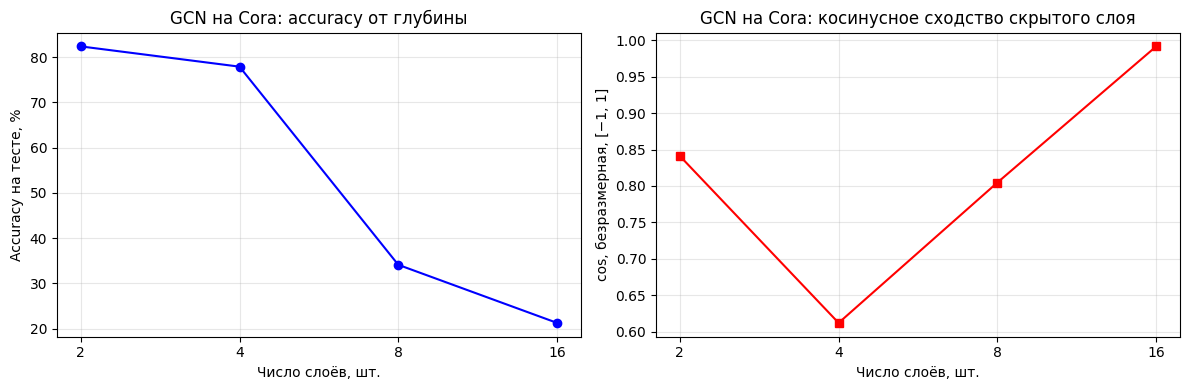

In [12]:
# Графики только для GCN: accuracy и косинусное сходство, среднее по 5 сидам
gcn = part3[part3.model == "GCN"].groupby("depth")
acc_list = gcn["test"].mean() * 100
sim_list = gcn["cos"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(DEPTHS, acc_list.values, "b-o")
ax1.set_xscale("log", base=2)
ax1.set_xticks(DEPTHS, DEPTHS)
ax1.set_xlabel("Число слоёв, шт.")
ax1.set_ylabel("Accuracy на тесте, %")
ax1.set_title("GCN на Cora: accuracy от глубины")
ax1.grid(True, alpha=0.3)

ax2.plot(DEPTHS, sim_list.values, "r-s")
ax2.set_xscale("log", base=2)
ax2.set_xticks(DEPTHS, DEPTHS)
ax2.set_xlabel("Число слоёв, шт.")
ax2.set_ylabel("cos, безразмерная, [−1, 1]")
ax2.set_title("GCN на Cora: косинусное сходство скрытого слоя")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Вывод

| Слоёв | Test acc GCN, % | Train acc GCN, % | Cos similarity | ‖h‖ | Test acc MLP, % |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 2  | 82.4 | 98.7 | 0.841 | 1.07 | 58.4 |
| 4  | 77.9 | 99.9 | 0.612 | 5.85 | 50.6 |
| 8  | 34.8 | 47.0 | 0.803 | 4.69 | 31.9 |
| 16 | 22.6 | 17.0 | **0.991** | 0.74 | 31.9 |

На 16 слоях у GCN представления **слиплись**: cos = 0.991, при этом активации живые. Каждый слой усредняет признаки по соседям, и после 16 таких усреднений векторы всех вершин почти совпадают по направлению, поэтому классы перестают различаться. Это проявляется уже на инициализации: cos необученной сети растёт с 0.40 до 0.98 с глубиной

Baseline MLP той же глубины показывает второй сценарий: **сеть не обучилась**. На 8–16 слоях MLP отвечает константой, сигнал от входа затухает в глубоком стеке. Графа у MLP нет, так что это проблема оптимизации, а не over-smoothing

## Бонус А

In [13]:
t0 = time.time()
full = datasets["Cora"][0].to(DEVICE)
new_nodes = full.test_mask
keep = ~new_nodes

sub_ei, _ = subgraph(
    keep, full.edge_index,
    relabel_nodes=True, num_nodes=full.num_nodes
)
sub = Data(
    x=full.x[keep],
    edge_index=sub_ei,
    y=full.y[keep],
    train_mask=full.train_mask[keep],
    val_mask=full.val_mask[keep],
)

# Проверка: в обучающем подграфе нет новых вершин и их рёбер
n_touching = (new_nodes[full.edge_index[0]] | new_nodes[full.edge_index[1]]).sum().item()
assert sub.num_nodes == full.num_nodes - new_nodes.sum().item()
assert sub.edge_index.size(1) == full.edge_index.size(1) - n_touching
assert sub.edge_index.max().item() < sub.num_nodes

print(f"полный граф: {full.num_nodes} вершин, {full.edge_index.size(1)} направленных рёбер")
print(
    f"обучающий подграф: {sub.num_nodes} вершин, {sub.edge_index.size(1)} рёбер "
    f"(удалено {n_touching} рёбер, касающихся новых вершин)"
)

C = datasets["Cora"].num_classes


def inductive(seed, kind="SAGE"):
    model = fit(make_model(kind, sub, C), sub, sub.train_mask, sub.val_mask)
    return {"acc": accuracy(model, full, new_nodes)}


def transductive(seed, kind="SAGE"):
    model = fit(make_model(kind, full, C), full, full.train_mask, full.val_mask)
    return {"acc": accuracy(model, full, new_nodes)}


bonusA = {
    "inductive": run_seeds(inductive),
    "transductive": run_seeds(transductive),
}
print(f"время: {time.time() - t0:.0f} с")


tableA = pd.DataFrame([
    {
        "Режим": "inductive",
        "Видела ли модель новые вершины при обучении?": "нет",
        "Accuracy на новых вершинах, %": mean_std(bonusA["inductive"]["acc"]),
    },
    {
        "Режим": "transductive",
        "Видела ли модель новые вершины при обучении?": "да, но без меток",
        "Accuracy на новых вершинах, %": mean_std(bonusA["transductive"]["acc"]),
    },
]).set_index("Режим")

tableA

полный граф: 2708 вершин, 10556 направленных рёбер
обучающий подграф: 1708 вершин, 4438 рёбер (удалено 6118 рёбер, касающихся новых вершин)
время: 76 с


,Видела ли модель новые вершины при обучении?,"Accuracy на новых вершинах, %"
Режим,,
inductive,нет,80.4 ± 0.6
transductive,"да, но без меток",80.6 ± 1.0


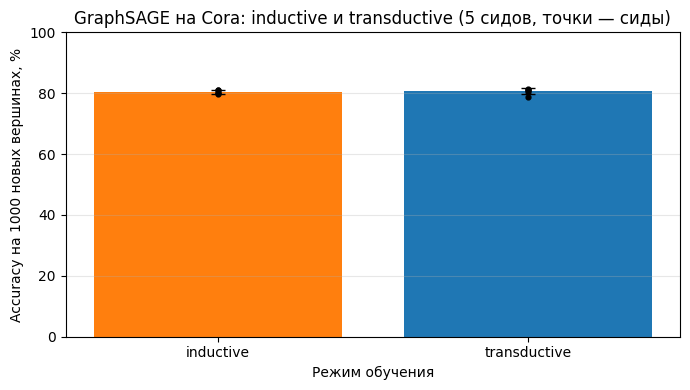

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))

labels = list(bonusA)
vals = [bonusA[k]["acc"] * 100 for k in labels]

ax.bar(
    labels,
    [v.mean() for v in vals],
    yerr=[v.std(ddof=1) for v in vals],
    capsize=5,
    color=["tab:orange", "tab:blue"],
)

for i, v in enumerate(vals):
    ax.scatter(np.full(len(v), i), v, color="black", s=12, zorder=3)

ax.set_ylim(0, 100)
ax.set_xlabel("Режим обучения")
ax.set_ylabel("Accuracy на 1000 новых вершинах, %")
ax.set_title("GraphSAGE на Cora: inductive и transductive (5 сидов, точки — сиды)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Вывод

Из вершин стандартного `test_mask` формируется отложенное множество новых вершин. В **inductive-режиме** эти вершины и все инцидентные им рёбра удаляются из графа перед обучением; в **transductive-режиме** модель обучается на полном графе, но метки доступны только у train-вершин

Обе модели без дообучения применяются к полному графу, а accuracy считается на одном и том же множестве новых вершин. Для каждого режима проведено по 5 запусков с разными сидами

| Режим | Видела ли модель новые вершины при обучении? | Accuracy на новых вершинах, % |
|---|---|:--:|
| inductive | нет | **80.4 ± 0.6** |
| transductive | да, но без меток | **80.6 ± 1.0** |

Разница между режимами составляет всего **0.2 п.п.** — 80.4% против 80.6% — и заметно меньше разброса между сидами, особенно у transductive-варианта. Поэтому корректнее говорить не о преимуществе transductive-режима, а о практически одинаковом качестве обоих подходов на Cora

Transductive-модель действительно видела рёбра новых вершин во время обучения, что могло бы дать дополнительный структурный сигнал. Однако на этом датасете он не привёл к измеримому приросту качества

Именно поэтому inductive-режим предпочтительнее практически тк он обучается на меньшем подграфе, не использует информацию о будущих test-вершинах и их связях, но показывает ту же accuracy

## Бонус B. Сколько разметки нужно графу

Для каждого сида строится свой случайный сплит. 20 % вершин уходят в тест, 10 % в валидацию, обучающие метки берутся из оставшихся 70 %. Доля размеченных вершин считается **от всего графа**: 1 %, 5 %, 20 %, 60 %

Выборка стратифицированная, чтобы при 1 % каждый класс имел хотя бы одну метку. Тест и валидация при этом не меняются, меняется только объём разметки.
Модели — двухслойный `MyGCNConv` и MLP того же размера 

In [15]:
FRACTIONS = [0.01, 0.05, 0.20, 0.60]


def label_split(y, frac, seed, test_frac=0.2, val_frac=0.1):
    g = torch.Generator().manual_seed(seed)
    n = y.size(0)
    perm = torch.randperm(n, generator=g)
    n_test, n_val = int(test_frac * n), int(val_frac * n)
    test_idx, val_idx, pool = perm[:n_test], perm[n_test:n_test + n_val], perm[n_test + n_val:]
    y_cpu = y.cpu()
    train_idx = []
    for c in y_cpu.unique():
        pool_c = pool[y_cpu[pool] == c]
        n_c = (y_cpu == c).sum().item()
        train_idx.append(pool_c[: max(1, round(frac * n_c))])
    masks = []
    for idx in [torch.cat(train_idx), val_idx, test_idx]:
        m = torch.zeros(n, dtype=torch.bool)
        m[idx] = True
        masks.append(m.to(y.device))
    return masks


t0 = time.time()
bonusB = []
for name, ds in datasets.items():
    data = ds[0].to(DEVICE)
    for frac in FRACTIONS:
        for kind in ["GCN", "MLP"]:
            def run_once(seed, kind=kind, frac=frac, data=data, ds=ds):
                tr, va, te = label_split(data.y, frac, seed)
                model = fit(make_model(kind, data, ds.num_classes), data, tr, va)
                return {"test": accuracy(model, data, te), "n_train": int(tr.sum())}
            df = run_seeds(run_once)
            df["dataset"], df["frac"], df["model"] = name, frac, kind
            bonusB.append(df)
bonusB = pd.concat(bonusB, ignore_index=True)
print(f"время: {time.time() - t0:.0f} с")

agg = bonusB.groupby(["dataset", "frac", "model"])["test"]
tableB = agg.apply(mean_std).unstack("model")
gap = (agg.mean().unstack("model").eval("GCN - MLP") * 100).round(1)
tableB["GCN − MLP, п.п."] = gap
tableB["меток, шт."] = bonusB.groupby(["dataset", "frac"])["n_train"].first()
tableB.index = tableB.index.set_levels([f"{int(f * 100)} %" for f in FRACTIONS], level="frac")
tableB

время: 1185 с


model                 GCN         MLP  GCN − MLP, п.п.  меток, шт.
dataset  frac                                                     
CiteSeer 1 %   54.3 ± 5.3  43.1 ± 4.3             11.1          34
         5 %   70.1 ± 1.4  60.2 ± 2.1              9.9         166
         20 %  74.0 ± 1.3  68.8 ± 1.2              5.1         666
         60 %  74.7 ± 0.9  71.8 ± 1.1              2.9        1997
Cora     1 %   68.9 ± 3.4  40.3 ± 3.8             28.6          27
         5 %   81.0 ± 1.2  57.9 ± 2.9             23.1         136
         20 %  84.4 ± 1.1  68.7 ± 1.9             15.6         542
         60 %  85.4 ± 1.7  72.1 ± 2.2             13.3        1626

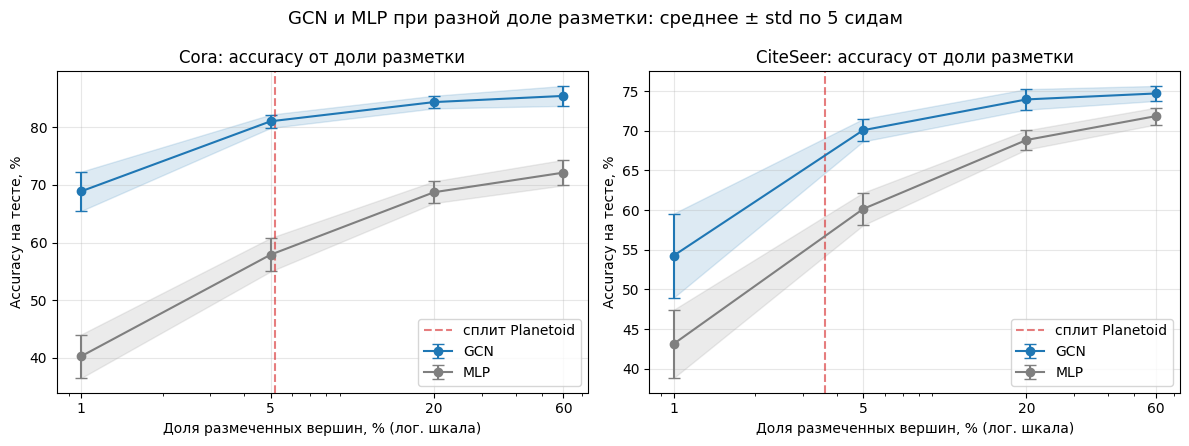

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
std_split = {"Cora": 140 / 2708, "CiteSeer": 120 / 3327}
for ax, name in zip(axes, datasets):
    for kind, color in [("GCN", "tab:blue"), ("MLP", "tab:gray")]:
        g = bonusB[(bonusB.dataset == name) & (bonusB.model == kind)].groupby("frac")["test"]
        m, s = g.mean() * 100, g.std(ddof=1) * 100
        x = m.index * 100
        ax.errorbar(x, m.values, yerr=s.values, marker="o", capsize=4, color=color, label=f"{kind}")
        ax.fill_between(x, m - s, m + s, color=color, alpha=0.15)
    ax.axvline(std_split[name] * 100, ls="--", color="tab:red", alpha=0.6, label="сплит Planetoid")
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 20, 60], ["1", "5", "20", "60"])
    ax.set_xlabel("Доля размеченных вершин, % (лог. шкала)")
    ax.set_ylabel("Accuracy на тесте, %")
    ax.set_title(f"{name}: accuracy от доли разметки")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("GCN и MLP при разной доле разметки: среднее ± std по 5 сидам", fontsize=13)
plt.tight_layout()
plt.show()

### Вывод

Доля размеченных вершин варьируется: 1%, 5%, 20% и 60% от всех вершин каждого датасета

| Датасет | Доля разметки | GCN, % | MLP, % | GCN − MLP, п.п. | Меток, шт. |
|:---|:---:|:---:|:---:|:---:|:---:|
| CiteSeer | 1%  | 54.3 ± 5.3 | 43.1 ± 4.3 | **+11.1** | 34 |
| CiteSeer | 5%  | 70.1 ± 1.4 | 60.2 ± 2.1 | **+9.9**  | 166 |
| CiteSeer | 20% | 74.0 ± 1.3 | 68.8 ± 1.2 | **+5.1**  | 666 |
| CiteSeer | 60% | 74.7 ± 0.9 | 71.8 ± 1.1 | **+2.9**  | 1997 |
| Cora     | 1%  | 68.9 ± 3.4 | 40.3 ± 3.8 | **+28.6** | 27 |
| Cora     | 5%  | 81.0 ± 1.2 | 57.9 ± 2.9 | **+23.1** | 136 |
| Cora     | 20% | 84.4 ± 1.1 | 68.7 ± 1.9 | **+15.6** | 542 |
| Cora     | 60% | 85.4 ± 1.7 | 72.1 ± 2.2 | **+13.3** | 1626 |

На обоих датасетах GCN стабильно превосходит MLP, но размер преимущества зависит от количества доступной разметки. На Cora разрыв максимален при малой доле меток: +28.6 п.п. при 1% и +23.1 п.п. при 5%; затем он сокращается до +15.6 п.п. при 20% и +13.3 п.п. при 60%. На CiteSeer тенденция та же, хотя разрыв меньше: от +11.1 п.п. при 1% до +2.9 п.п. при 60%

При малой разметке признаки bag-of-words дают слабый сигнал, поэтому структура рёбер становится особенно важной: GCN использует информацию о соседях и цитированиях, тогда как MLP опирается только на признаки вершины

При увеличении доли меток MLP лучше обучает отображение «признаки → класс», и разрыв уменьшается. Однако полного исчезновения преимущества графа не происходит. Это показывает, что структура графа остаётся полезным источником информации, а не только компенсирует нехватку меток

Более выраженный эффект на Cora объясняется тем, что её признаки сами по себе слабее разделяют классы, а структура цитирований несёт дополнительную дискриминативную информацию. На CiteSeer MLP справляется с признаками лучше, поэтому выигрыш от использования графа меньше